In [ ]:
pip install lightgbm

In [22]:
import lightgbm as lgb
import pandas as pd

df_main = pd.read_csv('/content/nasa_and_ataturk.csv')

df_main['date'] = pd.to_datetime(df_main['date'])

FEATURES = ['T2M', 'GWETROOT', 'PRECTOTCORR', 'SNODP', 'wse_lag1', 'wse_lag2', 'wse_lag3']
TARGET = 'target'
TEST_START_YEAR = 2020

model_df = df_main.copy()
model_df['year'] = model_df['date'].dt.year

test_years = sorted(model_df.loc[model_df['year'] >= TEST_START_YEAR, 'year'].unique())
results = []
model_result = []

for test_year in test_years:
  train = model_df[model_df['year'] < test_year]
  test = model_df[model_df['year'] == test_year]
  if test.empty or train.empty:
        continue

  X_train, y_train = train[FEATURES], train[TARGET]
  X_test = test[FEATURES]

  preds = {}
  for q, name in [(0.05, 'q05'), (0.5, 'q50'), (0.95, 'q95')]:
      model = lgb.LGBMRegressor(
          objective='quantile', alpha=q,
          n_estimators=100, max_depth=3, min_child_samples=5,
          verbose=-1
      )
      model.fit(X_train, y_train)
      preds[name] = model.predict(X_test)

  fold = test[['date', TARGET, 'wse']].copy()
  fold['q05'], fold['q50'], fold['q95'] = preds['q05'], preds['q50'], preds['q95']
  fold['test_year'] = test_year
  results.append(fold)

all_results = pd.concat(results).reset_index(drop=True)
all_results.rename(columns={'wse': 'baseline'}, inplace=True)

In [2]:
all_results

,date,target,baseline,q05,q50,q95,test_year
0,2020-01-01,535.675000,533.214500,531.122554,534.109740,535.599730,2020
1,2020-02-01,535.981250,533.277333,532.392664,534.769777,536.409709,2020
2,2020-03-01,536.305000,533.875000,531.776299,534.572017,535.693773,2020
3,2020-04-01,535.779500,535.675000,533.586408,535.831187,536.485909,2020
4,2020-05-01,534.138667,535.981250,532.760143,534.480526,535.356799,2020
...,...,...,...,...,...,...,...
72,2026-01-01,535.428000,531.064500,530.456042,532.464966,535.102115,2026
73,2026-02-01,536.478500,532.370500,531.083308,535.105710,535.565672,2026
74,2026-03-01,537.413333,533.975000,531.845419,535.535945,536.577995,2026
75,2026-04-01,537.753000,535.428000,531.970752,535.075367,536.564493,2026


In [3]:
mae_model = (all_results[TARGET] - all_results['q50']).abs().mean()
mae_baseline = (all_results[TARGET] - all_results['baseline']).abs().mean()
coverage = ((all_results[TARGET] >= all_results['q05']) &
            (all_results[TARGET] <= all_results['q95'])).mean()

print(f"Model MAE: {mae_model:.3f} m")
print(f"Baseline MAE: {mae_baseline:.3f} m")
print(f"q10-q90 kapsama oranı (hedef ~%90): {coverage*100:.1f}%")

Model MAE: 1.237 m
Baseline MAE: 1.612 m
q10-q90 kapsama oranı (hedef ~%90): 76.6%


In [4]:
all_results.groupby('test_year').apply(
    lambda g: (g['target'] - g['q50']).abs().mean()
).rename('MAE')

/tmp/ipykernel_3966/3886886039.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  all_results.groupby('test_year').apply(


,MAE
test_year,
2020,1.308510
2021,1.355480
2022,0.811705
2023,1.547992
2024,0.679346
2025,1.437101
2026,1.907810


In [5]:
all_results.groupby('test_year').apply(
    lambda g: (g['target'] - g['q50']).mean()
).rename('Bias (yön)')

/tmp/ipykernel_3966/3840263782.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  all_results.groupby('test_year').apply(


,Bias (yön)
test_year,
2020,-0.441940
2021,-0.480019
2022,-0.065654
2023,1.271551
2024,0.129206
2025,-0.700193
2026,1.907810


In [6]:
def get_risk_band(q50, percentiles):
    if q50 >= percentiles['p50']:
        return '🟢 Normal'
    elif q50 >= percentiles['p25']:
        return '🟡 Erken Uyarı'
    elif q50 >= percentiles['p10']:
        return '🟠 Hazırlık'
    else:
        return '🔴 Kriz'

In [7]:
def get_historical_percentiles(df, up_to_date):
    past_data = df[df['date'] < up_to_date]['wse']
    return {
        'p10': past_data.quantile(0.1),
        'p25': past_data.quantile(0.25),
        'p50': past_data.quantile(0.50),
    }

In [8]:
past_only = df_main[df_main['date'] < '2020-01-01']['wse']
percentiles_clean = {
    'p10': past_only.quantile(0.10),
    'p25': past_only.quantile(0.25),
    'p50': past_only.quantile(0.50),
}

print(percentiles_clean)

all_results['risk_band_clean'] = all_results['q50'].apply(
    lambda q50: get_risk_band(q50, percentiles_clean)
)
all_results[['date', 'target', 'q50', 'risk_band_clean']]
all_results

{'p10': np.float64(528.8234), 'p25': np.float64(530.9957499999999), 'p50': np.float64(534.0725)}


,date,target,baseline,q05,q50,q95,test_year,risk_band_clean
0,2020-01-01,535.675000,533.214500,531.122554,534.109740,535.599730,2020,🟢 Normal
1,2020-02-01,535.981250,533.277333,532.392664,534.769777,536.409709,2020,🟢 Normal
2,2020-03-01,536.305000,533.875000,531.776299,534.572017,535.693773,2020,🟢 Normal
3,2020-04-01,535.779500,535.675000,533.586408,535.831187,536.485909,2020,🟢 Normal
4,2020-05-01,534.138667,535.981250,532.760143,534.480526,535.356799,2020,🟢 Normal
...,...,...,...,...,...,...,...,...
72,2026-01-01,535.428000,531.064500,530.456042,532.464966,535.102115,2026,🟡 Erken Uyarı
73,2026-02-01,536.478500,532.370500,531.083308,535.105710,535.565672,2026,🟢 Normal
74,2026-03-01,537.413333,533.975000,531.845419,535.535945,536.577995,2026,🟢 Normal
75,2026-04-01,537.753000,535.428000,531.970752,535.075367,536.564493,2026,🟢 Normal


In [ ]:
all_results.to_csv('walk_forward_results.csv', index=False, encoding='utf-8')

import pickle
with open('percentiles.pkl', 'wb') as f:
  pickle.dump(percentiles_clean, f)

In [9]:
# En düşük gerçek seviyenin yaşandığı tarih
lowest_point = all_results.loc[all_results['target'].idxmin()]
print("En düşük nokta:")
print(lowest_point[['date', 'target']])

# O tarihten 3 ay önceki satır, modelin o an ne dediğini gösterir
# (çünkü 'date' satırı zaten targeti 3 ay sonrası için tahmin ediyor)
print("\nModelin bu düşüşten 3 ay önce verdiği tahmin:")
print(lowest_point[['date', 'q05', 'q50', 'q95', 'risk_band_clean']])

En düşük nokta:
date      2021-07-01 00:00:00
target               530.0555
Name: 18, dtype: object

Modelin bu düşüşten 3 ay önce verdiği tahmin:
date               2021-07-01 00:00:00
q05                         530.545438
q50                         533.044865
q95                         534.446986
risk_band_clean          🟡 Erken Uyarı
Name: 18, dtype: object


In [10]:
case_study = all_results[all_results['date'].between('2021-06-01', '2022-02-01')]
case_study[['date', 'target', 'q05', 'q50', 'q95', 'risk_band_clean']]

,date,target,q05,q50,q95,risk_band_clean
17,2021-06-01,530.39100,532.203111,533.487032,534.341489,🟡 Erken Uyarı
18,2021-07-01,530.05550,530.545438,533.044865,534.446986,🟡 Erken Uyarı
19,2021-08-01,530.41900,529.192661,531.690062,534.153905,🟡 Erken Uyarı
20,2021-09-01,530.72825,530.147111,531.138425,533.042341,🟡 Erken Uyarı
21,2021-10-01,530.39400,528.830718,529.980821,533.454510,🟠 Hazırlık
22,2021-11-01,530.30750,529.099134,530.069800,533.714137,🟠 Hazırlık
23,2021-12-01,530.80200,529.397048,530.740733,534.365818,🟠 Hazırlık
24,2022-01-01,531.35200,530.140032,532.436448,535.401052,🟡 Erken Uyarı
25,2022-02-01,531.70700,529.937711,531.726413,534.998680,🟡 Erken Uyarı


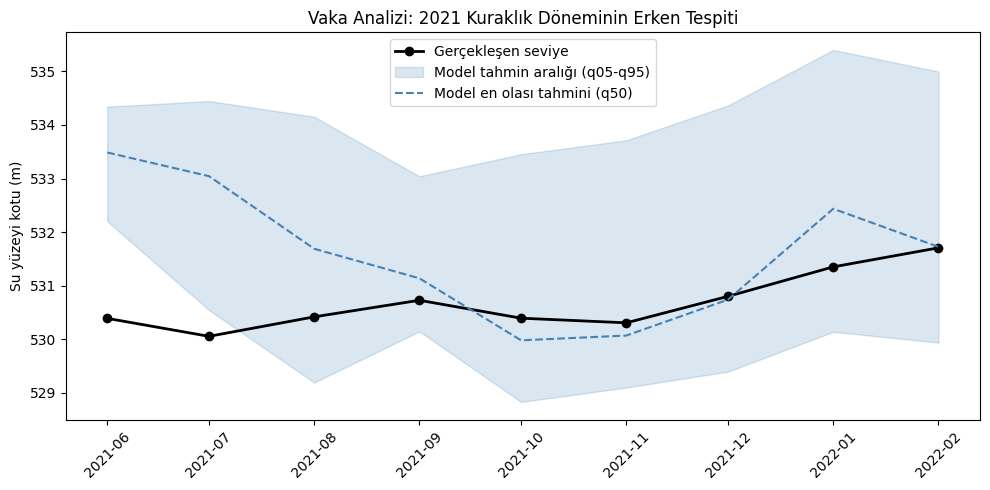

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(case_study['date'], case_study['target'], 'o-', color='black', label='Gerçekleşen seviye', linewidth=2)
ax.fill_between(case_study['date'], case_study['q05'], case_study['q95'], alpha=0.2, color='steelblue', label='Model tahmin aralığı (q05-q95)')
ax.plot(case_study['date'], case_study['q50'], '--', color='steelblue', label='Model en olası tahmini (q50)')
ax.set_title('Vaka Analizi: 2021 Kuraklık Döneminin Erken Tespiti')
ax.set_ylabel('Su yüzeyi kotu (m)')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('vaka_analizi.png', dpi=150)
plt.show()

In [11]:
import pandas as pd

# --- Sabitler (güncellenmiş) ---
NET_HEAD_AT_NORMAL = 144                # resmi kaynak: Atatürk net düşü ~144 m
MIN_OPERATIONAL_LEVEL = 526             # türbinlerin su almayı kestiği sınır
ELECTROLYZER_KWH_PER_KG = 53            # elektrolizör verimliliği (sektör standardı)
GREY_H2_CO2_PER_TON = 9                 # gri hidrojenin karbon ayak izi (literatür ortalaması)

QUARTERLY_AVG_GENERATION_GWH = (8.9 * 1000) / 4  # yıllık 8.9 TWh'nin çeyreği

# Tailwater'ı artık resmi düşü değerinden geriye türetiyoruz
TAILWATER_ELEV = percentiles_clean['p50'] - NET_HEAD_AT_NORMAL
head_normal = NET_HEAD_AT_NORMAL        # referans düşü, doğrudan resmi kaynaktan

# --- Ana hesap zinciri ---
def hydrogen_chain(q50):
    level_deviation = q50 - percentiles_clean['p50']           # 1. sapma (metre)
    deviation_ratio = level_deviation / head_normal             # orana çevir
    generation_gwh = QUARTERLY_AVG_GENERATION_GWH * deviation_ratio  # 2. GWh'ye çevir

    h2_potential_ton = (abs(generation_gwh) * 1_000_000) / ELECTROLYZER_KWH_PER_KG / 1000
    co2_avoided_ton = h2_potential_ton * GREY_H2_CO2_PER_TON

    direction = 'fırsat' if generation_gwh > 0 else 'kısıtlı'

    return pd.Series({
        'generation_gwh': generation_gwh,
        'h2_potential_ton': h2_potential_ton,
        'co2_avoided_ton': co2_avoided_ton,
        'direction': direction
    })

hydrogen_cols = all_results['q50'].apply(hydrogen_chain)
all_results = pd.concat([all_results, hydrogen_cols], axis=1)

# --- Sağlama kontrolü: q05, işletme sınırının (526 m) altına iniyor mu? ---
below_min_operational = all_results[all_results['q05'] < MIN_OPERATIONAL_LEVEL]
print(f"q05'i 526 m'nin altına inen ay sayısı: {len(below_min_operational)} / {len(all_results)}")
if len(below_min_operational) > 0:
    print("Bu aylarda doğrusal varsayım geçersiz olabilir — türbinler fiilen su alamayabilir:")
    print(below_min_operational[['date', 'q05', 'risk_band_clean']])

# --- İncelemen için tam tablo ---
all_results[['date', 'q50', 'risk_band_clean', 'generation_gwh', 'h2_potential_ton', 'co2_avoided_ton', 'direction']]


q05'i 526 m'nin altına inen ay sayısı: 0 / 77


,date,q50,risk_band_clean,generation_gwh,h2_potential_ton,co2_avoided_ton,direction
0,2020-01-01,534.109740,🟢 Normal,0.575405,10.856704,97.710338,fırsat
1,2020-02-01,534.769777,🟢 Normal,10.773896,203.281055,1829.529497,fırsat
2,2020-03-01,534.572017,🟢 Normal,7.718226,145.626904,1310.642133,fırsat
3,2020-04-01,535.831187,🟢 Normal,27.174160,512.719995,4614.479957,fırsat
4,2020-05-01,534.480526,🟢 Normal,6.304567,118.954095,1070.586854,fırsat
...,...,...,...,...,...,...,...
72,2026-01-01,532.464966,🟡 Erken Uyarı,-24.838632,468.653428,4217.880849,kısıtlı
73,2026-02-01,535.105710,🟢 Normal,15.964529,301.217525,2710.957721,fırsat
74,2026-03-01,535.535945,🟢 Normal,22.612263,426.646470,3839.818228,fırsat
75,2026-04-01,535.075367,🟢 Normal,15.495683,292.371380,2631.342422,fırsat


In [12]:
all_results = all_results.loc[:, ~all_results.columns.duplicated()].copy()
all_results.nsmallest(5, 'generation_gwh')[['date', 'q50', 'risk_band_clean', 'generation_gwh', 'co2_avoided_ton', 'direction']]

,date,q50,risk_band_clean,generation_gwh,co2_avoided_ton,direction
29,2022-06-01,529.877791,🟠 Hazırlık,-64.814082,11006.164932,kısıtlı
21,2021-10-01,529.980821,🟠 Hazırlık,-63.222122,10735.832004,kısıtlı
22,2021-11-01,530.069800,🟠 Hazırlık,-61.847278,10502.367971,kısıtlı
27,2022-04-01,530.075667,🟠 Hazırlık,-61.756616,10486.972521,kısıtlı
70,2025-11-01,530.279173,🟠 Hazırlık,-58.612167,9953.009571,kısıtlı


In [13]:
episode = all_results[all_results['date'].between('2021-06-01', '2022-02-01')]
print(f"2021 kuraklık dönemi toplam etki:")
print(f"Toplam H2 potansiyeli kaybı: {episode['h2_potential_ton'].sum():.1f} ton")
print(f"Toplam CO2 önlenebilir: {episode['co2_avoided_ton'].sum():.1f} ton")

2021 kuraklık dönemi toplam etki:
Toplam H2 potansiyeli kaybı: 6512.3 ton
Toplam CO2 önlenebilir: 58610.6 ton


In [17]:
all_results.to_csv('walk_forward_results_hydrogen.csv', index=False, encoding='utf-8')

In [23]:
importance_df = pd.DataFrame({
    'feature': FEATURES,  # ['T2M', 'PRECTOTCORR', 'GWETROOT', 'SNODP', 'wse_lag1', 'wse_lag2', 'wse_lag3']
    'importance': model.feature_importances_  # son eğitilen q50 modeli
}).sort_values('importance', ascending=False)

importance_df.to_csv('feature_importance.csv', index=False, encoding='utf-8')